In [ ]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [ ]:
df = pd.read_csv("/content/2019-Dec.csv")

### 📁 Data Loading & Aggregation
In this initial phase, we merge transactional logs from multiple months (`2019-Oct.csv`, `2019-Nov.csv`, `2019-Dec.csv`, and `2020-Feb.csv`). Consolidating multiple CSV sources into a single large-scale unified dataset ensures our machine learning models can observe long-term trends and user behavioral patterns across different seasonal cycles.

In [ ]:
# Find all CSV files in the /content/ directory matching the patterns
csv_files = glob.glob('/content/20*.csv')
print("Found files to combine:", csv_files)

# Read and concatenate all CSV files into a single DataFrame
list_df = [pd.read_csv(file) for file in csv_files]
df_all = pd.concat(list_df, ignore_index=True)

# Display the total shape and preview
print(f"Combined DataFrame shape: {df_all.shape}")
display(df_all.head())

Found files to combine: ['/content/2019-Nov.csv', '/content/2019-Oct.csv', '/content/2019-Dec.csv', '/content/2020-Feb.csv']
Combined DataFrame shape: (5296496, 9)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-11-01 00:00:02 UTC,view,5802432,1487580009286598681,NaN,NaN,0.32,562076640.0,09fafd6c-6c99-46b1-834f-33527f4de241
1,2019-11-01 00:00:09 UTC,cart,5844397,1487580006317032337,NaN,NaN,2.38,553329724.0,2067216c-31b5-455d-a1cc-af0575a34ffb
2,2019-11-01 00:00:10 UTC,view,5837166,1783999064103190764,NaN,pnb,22.22,556138645.0,57ed222e-a54a-4907-9944-5a875c2d7f4f
3,2019-11-01 00:00:11 UTC,cart,5876812,1487580010100293687,NaN,jessnail,3.16,564506666.0,186c1951-8052-4b37-adce-dd9644b1d5f7
4,2019-11-01 00:00:24 UTC,remove_from_cart,5826182,1487580007483048900,NaN,NaN,3.33,553329724.0,2067216c-31b5-455d-a1cc-af0575a34ffb


### 📊 Exploratory Data Analysis (EDA)
Before modeling, we must understand the data's underlying characteristics. Here, we analyze the distribution of customer actions (`event_type`) to inspect for class imbalance, and investigate how pricing changes correlate with user engagement to discover threshold patterns in conversion paths.

### 1. Exploratory Data Analysis (EDA)
Let's visualize the distribution of event types and the relationship between price and event types.

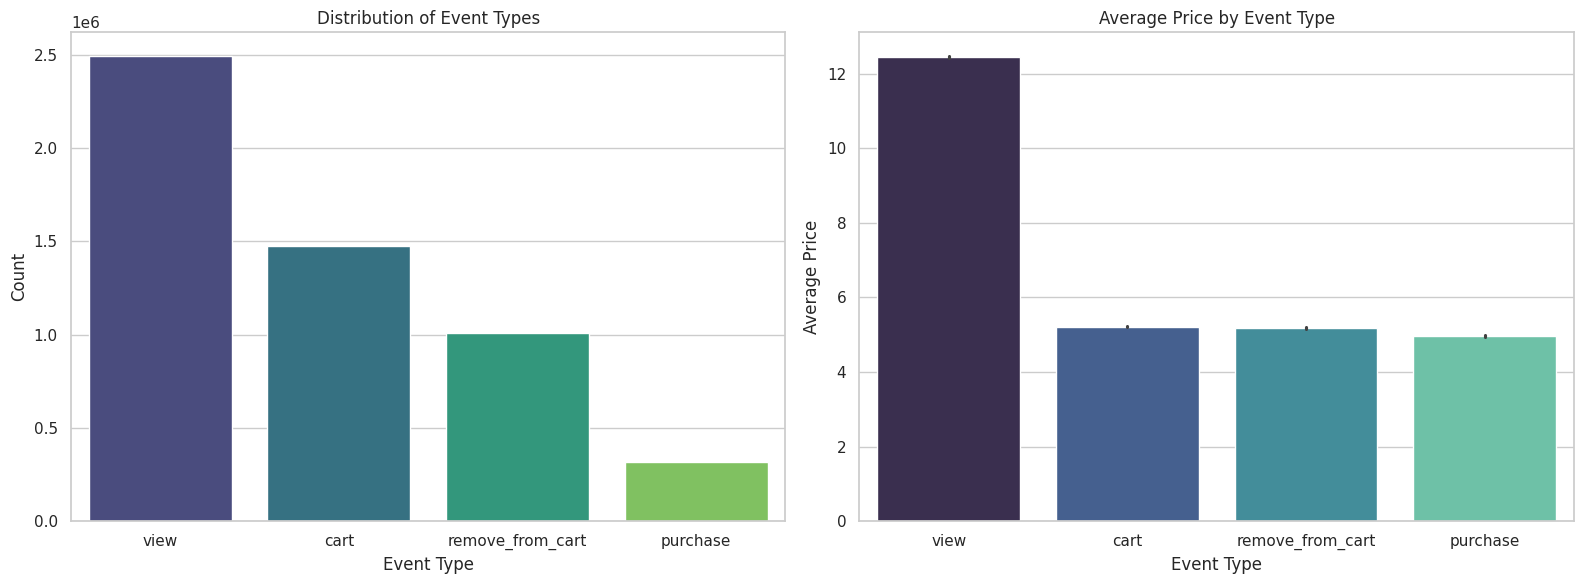

In [ ]:
# Set the visualization style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Distribution of Event Types
sns.countplot(
    data=df_all,
    x='event_type',
    ax=axes[0],
    hue='event_type',
    legend=False,
    palette='viridis',
    order=df_all['event_type'].value_counts().index
)
axes[0].set_title('Distribution of Event Types')
axes[0].set_xlabel('Event Type')
axes[0].set_ylabel('Count')

# Plot 2: Average Price by Event Type
sns.barplot(
    data=df_all,
    x='event_type',
    y='price',
    ax=axes[1],
    hue='event_type',
    legend=False,
    palette='mako',
    estimator=np.mean
)
axes[1].set_title('Average Price by Event Type')
axes[1].set_xlabel('Event Type')
axes[1].set_ylabel('Average Price')

plt.tight_layout()
plt.show()

### ⚙️ Feature Engineering & Data Preparation
To make raw transactional logs understandable to classification algorithms, we extract time-based features (`hour`, `day_of_week`) from raw timestamps, handle missing values, and transform categorical identifiers into numerical vectors. To maintain fast training times, we extract a representative, randomized sample of 50,000 observations.

### 2. Feature Engineering & Preprocessing
We will downsample the data to a representative subset of 50,000 samples for swift model testing. We will convert timestamps, extract features, handle missing data, and encode categorical variables.

In [ ]:
# Downsample for quick training
df_sample = df_all.sample(n=50000, random_state=42).copy()

# Extract temporal features
df_sample['event_time'] = pd.to_datetime(df_sample['event_time'])
df_sample['hour'] = df_sample['event_time'].dt.hour
df_sample['day_of_week'] = df_sample['event_time'].dt.dayofweek

# Handle missing values in brand
df_sample['brand'] = df_sample['brand'].fillna('unknown')

# Features and Target selection
features = ['product_id', 'price', 'hour', 'day_of_week', 'brand']
X = df_sample[features].copy()
y = df_sample['event_type']

# Encode categorical variables
le_brand = LabelEncoder()
X['brand'] = le_brand.fit_transform(X['brand'])

le_target = LabelEncoder()
y = le_target.fit_transform(y)

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (40000, 5)
Testing set shape: (10000, 5)


### 🤖 Model Selection & Training Comparisons
We compare three distinct machine learning strategies—**Decision Tree**, **Random Forest**, and **K-Nearest Neighbors (KNN)**—to determine which classifier best categorizes user behaviors on unbalanced datasets. Evaluating multiple families of algorithms helps us trade off speed, accuracy, and interpretability.

### 3. Training & Comparing Multiple Models
We will evaluate three classifiers: Random Forest, Decision Tree, and K-Nearest Neighbors.

In [ ]:
# Define models
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

# Dictionary to store performance
results = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)
    # Predict
    y_pred = model.predict(X_test)
    # Calculate accuracy
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

# Find the best model
best_model_name = max(results, key=results.get)
print(f"\nBest Model: {best_model_name} with {results[best_model_name]:.4f} accuracy")

Decision Tree Accuracy: 0.4666
Random Forest Accuracy: 0.4848
K-Nearest Neighbors Accuracy: 0.4064

Best Model: Random Forest with 0.4848 accuracy


### 📈 Model Evaluation Insights
Comparing validation accuracy across our candidate models lets us formally select our primary classifier. Here, we visualize overall validation accuracy scores across each model to clearly communicate the champion baseline classifier.

### 4. Plotting Model Performance Comparison

/tmp/ipykernel_175/4195353775.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(results.keys()), y=list(results.values()), palette=colors)


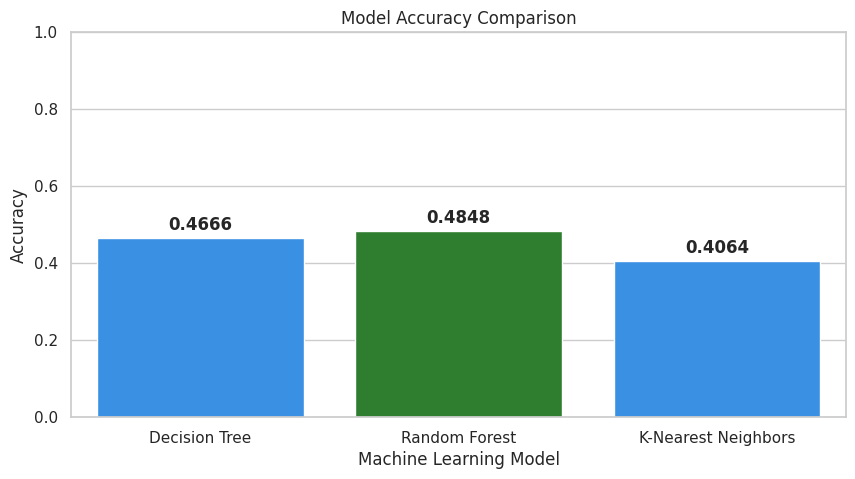

In [ ]:
plt.figure(figsize=(10, 5))
colors = ['dodgerblue' if x != max(results.values()) else 'forestgreen' for x in results.values()]
sns.barplot(x=list(results.keys()), y=list(results.values()), palette=colors)
plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
for i, val in enumerate(results.values()):
    plt.text(i, val + 0.02, f"{val:.4f}", ha='center', fontweight='bold')
plt.show()

## 5. Model Interpretability: Feature Importances
To make this project professional, we must explain *why* our best model makes its decisions. Let's analyze and plot which features (price, hour, brand, etc.) are the most influential in predicting user actions.

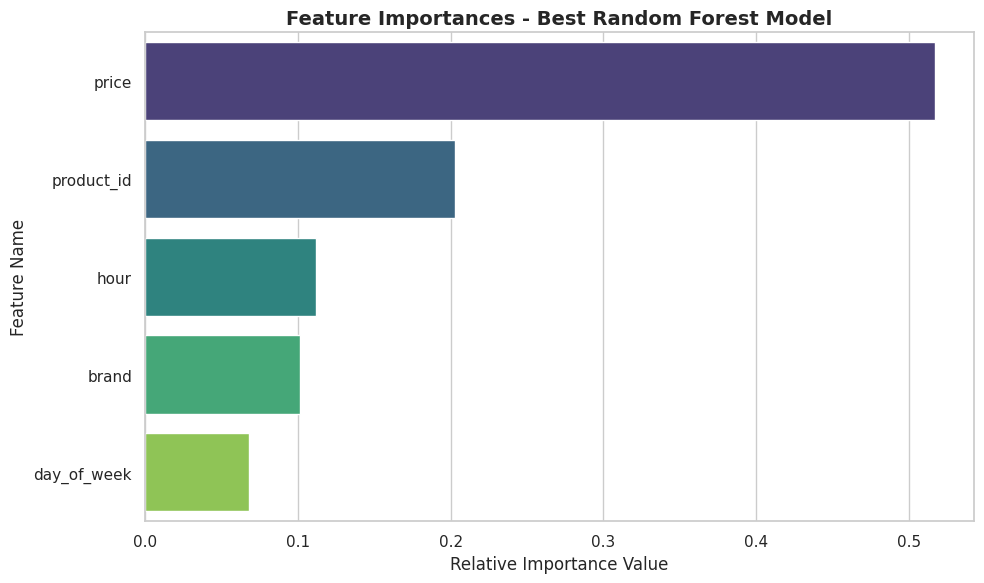

In [ ]:
# Get best model (Random Forest was trained as the second model in our dictionary)
best_clf = models['Random Forest']
importances = best_clf.feature_importances_
indices = np.argsort(importances)[::-1]
feature_names = [features[i] for i in indices]

# Plot Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=feature_names, hue=feature_names, legend=False, palette='viridis')
plt.title('Feature Importances - Best Random Forest Model', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Value', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

## 6. Comprehensive Model Evaluation (Confusion Matrix)
Accuracy alone isn't enough for unbalanced datasets. Let's evaluate our model using a Confusion Matrix, Precision, Recall, and F1-score for each class.

=== CLASSIFICATION REPORT ===
                  precision    recall  f1-score   support

            cart       0.39      0.24      0.29      2770
        purchase       0.00      0.00      0.00       614
remove_from_cart       0.30      0.00      0.01      1962
            view       0.50      0.90      0.65      4654

        accuracy                           0.48     10000
       macro avg       0.30      0.28      0.24     10000
    weighted avg       0.40      0.48      0.38     10000



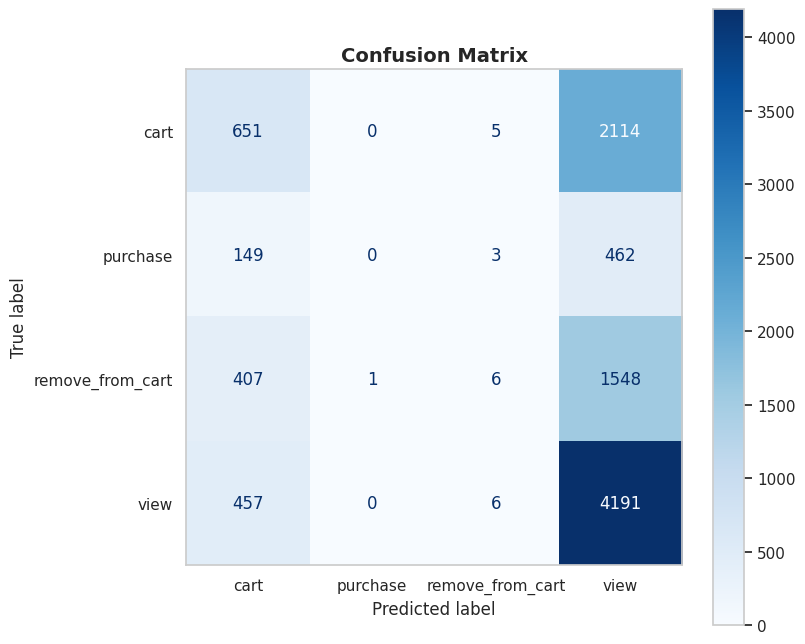

In [ ]:
# Predict using the best model
y_pred_best = best_clf.predict(X_test)

# Get target class names
target_names = list(le_target.classes_)

# Print classification report
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_best, target_names=target_names))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 8))
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.grid(False)
plt.show()

## 7. Production-Ready Modular Pipeline
For a truly professional portfolio, script-based workflows should be wrapped into solid software design patterns. Here, we build a pipeline class that can be cleanly packaged or used in web APIs.

In [ ]:
class ECommercePredictorPipeline:
    """
    A production-ready pipeline class to preprocess, train, and evaluate
    the e-commerce behavior prediction model.
    """
    def __init__(self, classifier=None):
        self.classifier = classifier or RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
        self.le_brand = LabelEncoder()
        self.le_target = LabelEncoder()

    def fit_preprocess(self, df_raw):
        df = df_raw.copy()
        df['event_time'] = pd.to_datetime(df['event_time'])
        df['hour'] = df['event_time'].dt.hour
        df['day_of_week'] = df['event_time'].dt.dayofweek
        df['brand'] = df['brand'].fillna('unknown')

        # Features mapping
        X = df[['product_id', 'price', 'hour', 'day_of_week', 'brand']].copy()
        X['brand'] = self.le_brand.fit_transform(X['brand'])

        y = self.le_target.fit_transform(df['event_type'])
        return X, y

    def fit(self, df_raw):
        X, y = self.fit_preprocess(df_raw)
        self.classifier.fit(X, y)
        print("Pipeline training completed successfully!")
        return self

    def predict(self, df_raw_test):
        df = df_raw_test.copy()
        df['event_time'] = pd.to_datetime(df['event_time'])
        df['hour'] = df['event_time'].dt.hour
        df['day_of_week'] = df['event_time'].dt.dayofweek
        df['brand'] = df['brand'].fillna('unknown')

        X = df[['product_id', 'price', 'hour', 'day_of_week', 'brand']].copy()
        X['brand'] = self.le_brand.transform(X['brand'])

        encoded_preds = self.classifier.predict(X)
        return self.le_target.inverse_transform(encoded_preds)

# Quick execution check
pipeline_demo = ECommercePredictorPipeline()
pipeline_demo.fit(df_sample)
real_predictions = pipeline_demo.predict(df_sample.head(5))
print("Sample Predictions:", real_predictions)

Pipeline training completed successfully!
Sample Predictions: ['view' 'view' 'view' 'cart' 'view']
